In [2]:
import sys
sys.path.append('../')

In [3]:
from ice_fx.infrastructure.instrument_collection import instrumentCollection as ic
from ice_fx.oanda_api.oanda_api import OandaApi
from ice_fx.infrastructure.collect_data import run_collection
from findicator import (atr, bollinger_bands, macd, impulse_system, ema_channel,
                        elder_ray, stochastic_oscillator, force_index, rsi)
# from findicator import stochastic_oscillator
from chronofusion.utils.errors import InvalidArgumentError, NonOverlappingData, NotAvailableData

api = OandaApi()
ic.create_file(api.get_account_instruments(), "./test_env_data")
ic.load_instruments("./test_env_data")
# ic.print_instruments()


In [4]:
# run_collection(ic, api, curr_list=["USD", "EUR"],
#                granlurality_list=['M5', "M30"],
#                save_to='./test_env_data/')


In [5]:
import pandas as pd
m5_data = pd.read_pickle('./test_env_data/EUR_USD_M5.pkl')
m30_data = pd.read_pickle('./test_env_data/EUR_USD_M30.pkl')

In [6]:
m30_data_filtered = m30_data[['time', 'volume', 'mid_o', 'mid_h', 'mid_l', 'mid_c']].copy()
m5_data_filtered = m5_data[['time', 'volume', 'mid_o', 'mid_h', 'mid_l', 'mid_c']].copy()

In [37]:
# m5_data_filtered[12000:15000].head(20)
#  2016-03-04 18:00:00+00:00

In [8]:
m30_data_filtered.head()

,time,volume,mid_o,mid_h,mid_l,mid_c
0,2016-01-07 00:00:00+00:00,335,1.07764,1.07832,1.07759,1.07790
1,2016-01-07 00:30:00+00:00,207,1.07786,1.07810,1.07744,1.07778
2,2016-01-07 01:00:00+00:00,1323,1.07776,1.07990,1.07748,1.07966
3,2016-01-07 01:30:00+00:00,1844,1.07968,1.08100,1.07931,1.08029
4,2016-01-07 02:00:00+00:00,854,1.08026,1.08086,1.07996,1.08018


In [9]:
class TimeFrameWindowGen:
    def __init__(self, 
                 higher_tf_data:pd.DataFrame, 
                 lower_tf_data:pd.DataFrame, 
                 higher_window_size:int = 50, 
                 lower_window_size:int = 50,
                 htf_start_index=0):
        
        # self.timestep = 0
        self.htf_data = higher_tf_data
        self.ltf_data = lower_tf_data
        self.h_window_size = higher_window_size
        self.l_window_size = lower_window_size
        self.alignment(htf_start_index=htf_start_index)

    def alignment(self, htf_start_index: int):
        self.higher_last_candle_index = self.h_window_size - 1 + htf_start_index
        if self.higher_last_candle_index >= self.htf_data.shape[0]:
            raise NotAvailableData(index=self.higher_last_candle_index, data_frame_scale='higher')
        time_to_align = self.htf_data['time'].iloc[self.higher_last_candle_index]
        # print(self.htf_data.iloc[self.higher_last_candle_index])
        aligned_index = self.ltf_data.index[self.ltf_data["time"] == time_to_align]
        if aligned_index.empty:
            raise NonOverlappingData()
        else:
            self.lower_last_candle_index = aligned_index[0]

    def generate(self):
        
        start = self.higher_last_candle_index - self.h_window_size + 1
        end = self.higher_last_candle_index + 1
        if end >= self.htf_data.shape[0]:
            raise NotAvailableData(index=end, data_frame_scale='higher')
        if start >= self.htf_data.shape[0]:
            raise NotAvailableData(index=start, data_frame_scale='higher')
        
        higher_fraction = self.htf_data[start:end]


        start = self.lower_last_candle_index - self.l_window_size + 1 
        end = self.lower_last_candle_index + 1
        if end >= self.ltf_data.shape[0]:
           raise NotAvailableData(index=end, data_frame_scale='lower')
        if start >= self.ltf_data.shape[0]:
           raise NotAvailableData(index=start, data_frame_scale='lower')
        
        lower_fraction = self.ltf_data[start:end]
            
        # self.timestep += 1
        self.lower_last_candle_index += 1

        higher_time_delta = self.htf_data['time'].iloc[self.higher_last_candle_index] - \
                            self.htf_data['time'].iloc[self.higher_last_candle_index-1]
        
        if self.htf_data['time'].iloc[self.higher_last_candle_index] + higher_time_delta <=\
           self.ltf_data['time'].iloc[self.lower_last_candle_index]:
            
            self.higher_last_candle_index += 1
        

        return higher_fraction, lower_fraction
    
    def get_current_price(self):
        curr_price_index  = self.lower_last_candle_index - 1 
        return self.ltf_data['mid_c'].iloc[curr_price_index]
        

In [10]:
window_generator = TimeFrameWindowGen(m30_data_filtered, m5_data_filtered,
                                      higher_window_size=5, lower_window_size=5)

for i in range(20):

    if i == 10:
        print('\n\n\n')
        window_generator.alignment(htf_start_index=5000)
        
    h, l = window_generator.generate()
    
    curr_price = window_generator.get_current_price()
    print(h, '\n')
    print(l, '\n')
    print(curr_price, '\n *************************')
    

                       time  volume    mid_o    mid_h    mid_l    mid_c
0 2016-01-07 00:00:00+00:00     335  1.07764  1.07832  1.07759  1.07790
1 2016-01-07 00:30:00+00:00     207  1.07786  1.07810  1.07744  1.07778
2 2016-01-07 01:00:00+00:00    1323  1.07776  1.07990  1.07748  1.07966
3 2016-01-07 01:30:00+00:00    1844  1.07968  1.08100  1.07931  1.08029
4 2016-01-07 02:00:00+00:00     854  1.08026  1.08086  1.07996  1.08018 

                        time  volume    mid_o    mid_h    mid_l    mid_c
20 2016-01-07 01:40:00+00:00     334  1.08027  1.08099  1.08027  1.08079
21 2016-01-07 01:45:00+00:00     387  1.08076  1.08097  1.07937  1.07992
22 2016-01-07 01:50:00+00:00     369  1.07994  1.08100  1.07992  1.08100
23 2016-01-07 01:55:00+00:00     267  1.08098  1.08098  1.08029  1.08029
24 2016-01-07 02:00:00+00:00     210  1.08026  1.08068  1.08026  1.08027 

1.08027 
 *************************
                       time  volume    mid_o    mid_h    mid_l    mid_c
0 2016-01-07 00:00

In [ ]:
# while l is not None:
#     h, l = window_generator.generate()
#     print('hi')
#     # print(h, '\n')
#     # print(l, '\n *************************')

In [11]:
# a = ema_channel(m5_data_filtered['mid_c'], ema_period=26, use_atr=False)
# indicators = pd.DataFrame()
# indicators['ima'] = a
# indicators


In [6]:
import torch
from chronofusion.models.transformer import MultiScaleTransformer

# === Fake input specs ===
# Assume:
# - high frequency: 5min timeframe, window size 50
# - low frequency:  30min timeframe, window size 50
# - multivariate: e.g., 6 features per scale

batch_size = 8
seq_len = 50
input_dim_high = 6
input_dim_low = 6

# === Fake data ===
x_high = torch.randn(batch_size, seq_len, input_dim_high)  # 5min scale
x_low  = torch.randn(batch_size, seq_len, input_dim_low)   # 30min scale



x_high[0][0]

tensor([ 1.0452,  0.0318,  0.2438, -0.8902,  0.2385,  0.4550])

In [3]:
# === Model ===
model = MultiScaleTransformer(
    input_dim_low=input_dim_low,
    input_dim_high=input_dim_high,
    d_model=64,       # hidden size per scale
    nhead=4,
    num_layers=2,
    output_dim=100    # final embedding size per step
)

# === Forward pass ===
output = model(x_low, x_high)

print("Output shape:", output.shape)
# Output shape: torch.Size([8, 50, 100])

# === Use for classification ===
# Example: pool along time dimension, then pass to a classifier
pooled = torch.mean(output, dim=1)  # (batch_size, 100)

print("Pooled shape:", pooled.shape)
# torch.Size([8, 100])

Output shape: torch.Size([8, 50, 100])
Pooled shape: torch.Size([8, 100])


In [ ]:
# import numpy as np
# import pandas as pd
# from collections import deque
# import gym
# from gym import spaces
# import talib

# class ForexTradingEnv(gym.Env):
#     """
#     Forex Trading Environment for DQN
#     Actions: 1=close, 2=buy, 3=sell, 4=hold
#     Termination: 2% loss or 6% profit on trade
#     """
    
#     def __init__(self, data, initial_balance=10000, lot_size=0.1, 
#                  stop_loss_pct=0.02, take_profit_pct=0.06, 
#                  lookback_window=20, transaction_cost=0.0001):
#         super(ForexTradingEnv, self).__init__()
        
#         self.data = data.reset_index(drop=True)
#         self.initial_balance = initial_balance
#         self.lot_size = lot_size
#         self.stop_loss_pct = stop_loss_pct
#         self.take_profit_pct = take_profit_pct
#         self.lookback_window = lookback_window
#         self.transaction_cost = transaction_cost
        
#         # Position tracking
#         self.current_position = 0.0  # -lot_size, 0.0, or +lot_size
#         self.entry_price = None
#         self.current_step = 0
#         self.current_balance = initial_balance
#         self.trade_history = []
#         self.steps_in_trade = 0
        
#         # Action space: 1=close, 2=buy, 3=sell, 4=hold
#         self.action_space = spaces.Discrete(4)
        
#         # Calculate technical indicators
#         self._calculate_indicators()
        
#         # State space (market features + position features)
#         self.observation_space = spaces.Box(
#             low=-np.inf, high=np.inf, 
#             shape=(10,), dtype=np.float32
#         )
        
#         # Episode tracking
#         self.max_steps = len(self.data) - self.lookback_window - 1
        
#     def _calculate_indicators(self):
#         """Calculate technical indicators for the entire dataset"""
#         close_prices = self.data['close'].values
#         high_prices = self.data['high'].values
#         low_prices = self.data['low'].values
        
#         # Technical indicators
#         self.data['rsi'] = talib.RSI(close_prices, timeperiod=14)
#         self.data['macd'], self.data['macd_signal'], _ = talib.MACD(close_prices)
#         self.data['bb_upper'], self.data['bb_middle'], self.data['bb_lower'] = talib.BBANDS(close_prices)
#         self.data['sma_20'] = talib.SMA(close_prices, timeperiod=20)
#         self.data['atr'] = talib.ATR(high_prices, low_prices, close_prices, timeperiod=14)
        
#         # Price changes
#         self.data['price_change_1'] = self.data['close'].pct_change(1)
#         self.data['price_change_5'] = self.data['close'].pct_change(5)
        
#         # Fill NaN values
#         self.data.bfill(inplace=True)
        
#     def reset(self):
#         """Reset environment to initial state"""
#         self.current_balance = self.initial_balance
#         self.current_position = 0.0
#         self.entry_price = None
#         self.current_step = 0 # self.lookback_window
#         self.trade_history = []
#         self.steps_in_trade = 0
        
#         return self._get_state()
    
#     def _get_state(self):
#         """Get current state representation"""
#         current_data = self.data.iloc[self.current_step]
        
#         # Market features
#         market_features = [
#             current_data['close'],
#             current_data['price_change_1'],
#             current_data['price_change_5'],
#             current_data['rsi'] / 100.0,  # normalize RSI
#             current_data['macd'],
#             (current_data['close'] - current_data['bb_lower']) / (current_data['bb_upper'] - current_data['bb_lower']),  # BB position
#             current_data['atr']
#         ]
        
#         # Position features
#         position_features = [
#             self.current_position / self.lot_size,  # -1, 0, or +1
#             self._calculate_unrealized_pnl() / self.initial_balance,  # normalized unrealized P&L
#             self.steps_in_trade / 100.0  # normalized time in trade
#         ]
        
#         state = np.array(market_features + position_features, dtype=np.float32)
#         return state
    
#     def _calculate_unrealized_pnl(self):
#         """Calculate unrealized profit/loss"""
#         if self.current_position == 0.0 or self.entry_price is None:
#             return 0.0
        
#         current_price = self.data.iloc[self.current_step]['close']
        
#         if self.current_position > 0:  # Long position
#             pnl = (current_price - self.entry_price) * abs(self.current_position) * 100000
#         else:  # Short position
#             pnl = (self.entry_price - current_price) * abs(self.current_position) * 100000
            
#         return pnl
    
#     def _get_valid_actions(self):
#         """Get valid actions based on current position"""
#         if self.current_position == 0.0:  # Flat
#             return [0, 1, 2]  # close(no-op), buy, sell
#         else:  # In position
#             return [0, 3]  # close, hold
    
#     def step(self, action):
#         """Execute one step in the environment"""
#         current_price = self.data.iloc[self.current_step]['close']
        
#         # Execute action
#         reward = self._execute_action(action, current_price)
        
#         # Check termination conditions
#         done = self._check_termination(current_price)
        
#         # Move to next step
#         self.current_step += 1
#         if self.current_position != 0:
#             self.steps_in_trade += 1
        
#         # Check if we've reached end of data
#         if self.current_step >= self.max_steps:
#             done = True
#             # Force close any open position
#             if self.current_position != 0:
#                 reward += self._close_position(current_price)
        
#         next_state = self._get_state() if not done else np.zeros(10)
        
#         info = {
#             'current_balance': self.current_balance,
#             'current_position': self.current_position,
#             'unrealized_pnl': self._calculate_unrealized_pnl(),
#             'steps_in_trade': self.steps_in_trade
#         }
        
#         return next_state, reward, done, info
    
#     def _execute_action(self, action, current_price):
#         """Execute the given action and return reward"""
#         valid_actions = self._get_valid_actions()
        
#         # Map action indices: 0=close, 1=buy, 2=sell, 3=hold
#         if action not in valid_actions:
#             return -0.01  # Invalid action penalty
        
#         reward = 0.0
        
#         if action == 0:  # Close position
#             if self.current_position != 0:
#                 reward = self._close_position(current_price)
#             # If already flat, no penalty
            
#         elif action == 1:  # Buy
#             if self.current_position == 0:
#                 reward = self._open_position(current_price, self.lot_size)
            
#         elif action == 2:  # Sell
#             if self.current_position == 0:
#                 reward = self._open_position(current_price, -self.lot_size)
                
#         elif action == 3:  # Hold
#             if self.current_position != 0:
#                 # Small time penalty + unrealized P&L signal
#                 unrealized_pnl = self._calculate_unrealized_pnl()
#                 reward = -0.0001 + (unrealized_pnl / self.initial_balance) * 0.01
            
#         return reward
    
#     def _open_position(self, price, position_size):
#         """Open a new position"""
#         self.current_position = position_size
#         self.entry_price = price
#         self.steps_in_trade = 0
        
#         # Transaction cost
#         transaction_cost = abs(position_size) * 100000 * self.transaction_cost
#         self.current_balance -= transaction_cost
        
#         return -0.001  # Small penalty for opening position
    
#     def _close_position(self, price):
#         """Close current position and return realized P&L"""
#         if self.current_position == 0:
#             return 0.0
        
#         # Calculate realized P&L
#         if self.current_position > 0:  # Long position
#             pnl = (price - self.entry_price) * abs(self.current_position) * 100000
#         else:  # Short position
#             pnl = (self.entry_price - price) * abs(self.current_position) * 100000
        
#         # Transaction cost
#         transaction_cost = abs(self.current_position) * 100000 * self.transaction_cost
#         net_pnl = pnl - transaction_cost
        
#         # Update balance
#         self.current_balance += net_pnl
        
#         # Record trade
#         self.trade_history.append({
#             'entry_price': self.entry_price,
#             'exit_price': price,
#             'position_size': self.current_position,
#             'pnl': net_pnl,
#             'steps_in_trade': self.steps_in_trade
#         })
        
#         # Reset position
#         self.current_position = 0.0
#         self.entry_price = None
#         self.steps_in_trade = 0
        
#         # Return normalized reward
#         return net_pnl / self.initial_balance
    
#     def _check_termination(self, current_price):
#         """Check if episode should terminate"""
#         if self.current_position == 0:
#             return False
        
#         unrealized_pnl = self._calculate_unrealized_pnl()
#         trade_value = abs(self.current_position) * 100000 * self.entry_price
        
#         # Stop loss: 2% loss
#         if unrealized_pnl <= -trade_value * self.stop_loss_pct:
#             self._close_position(current_price)
#             return True
        
#         # Take profit: 6% profit
#         if unrealized_pnl >= trade_value * self.take_profit_pct:
#             self._close_position(current_price)
#             return True
        
#         return False
    
#     def render(self, mode='human'):
#         """Render current state"""
#         current_price = self.data.iloc[self.current_step]['close']
#         unrealized_pnl = self._calculate_unrealized_pnl()
        
#         print(f"Step: {self.current_step}")
#         print(f"Price: {current_price:.5f}")
#         print(f"Position: {self.current_position}")
#         print(f"Balance: ${self.current_balance:.2f}")
#         print(f"Unrealized P&L: ${unrealized_pnl:.2f}")
#         print(f"Steps in trade: {self.steps_in_trade}")
#         print("-" * 30)
    
#     def get_trade_statistics(self):
#         """Get trading statistics"""
#         if not self.trade_history:
#             return {}
        
#         trades_df = pd.DataFrame(self.trade_history)
        
#         stats = {
#             'total_trades': len(trades_df),
#             'winning_trades': len(trades_df[trades_df['pnl'] > 0]),
#             'losing_trades': len(trades_df[trades_df['pnl'] < 0]),
#             'total_pnl': trades_df['pnl'].sum(),
#             'average_pnl': trades_df['pnl'].mean(),
#             'max_profit': trades_df['pnl'].max(),
#             'max_loss': trades_df['pnl'].min(),
#             'win_rate': len(trades_df[trades_df['pnl'] > 0]) / len(trades_df) * 100,
#             'average_trade_duration': trades_df['steps_in_trade'].mean()
#         }
        
#         return stats


# # Example usage and testing
# if __name__ == "__main__":
#     # Create sample data (replace with your actual forex data)
#     np.random.seed(42)
#     n_samples = 1000
    
#     # Generate sample OHLC data
#     base_price = 1.1000
#     price_changes = np.random.normal(0, 0.0001, n_samples)
#     prices = base_price + np.cumsum(price_changes)
    
#     sample_data = pd.DataFrame({
#         'timestamp': pd.date_range('2023-01-01', periods=n_samples, freq='1min'),
#         'open': prices + np.random.normal(0, 0.00005, n_samples),
#         'high': prices + np.abs(np.random.normal(0, 0.00005, n_samples)),
#         'low': prices - np.abs(np.random.normal(0, 0.00005, n_samples)),
#         'close': prices,
#         'volume': np.random.randint(100, 1000, n_samples)
#     })
    
#     # Initialize environment
#     env = ForexTradingEnv(sample_data)
    
#     # Test environment
#     state = env.reset()
#     print("Initial state shape:", state.shape)
#     print("Action space:", env.action_space.n)
    
#     # Run a few random steps
#     for i in range(10):
#         action = env.action_space.sample()
#         valid_actions = env._get_valid_actions()
#         action = np.random.choice(valid_actions)
        
#         next_state, reward, done, info = env.step(action)
        
#         print(f"Step {i+1}: Action={action}, Reward={reward:.6f}, Done={done}")
#         print(f"Position: {info['current_position']}, Balance: ${info['current_balance']:.2f}")
        
#         if done:
#             print("Episode terminated!")
#             break
    
#     # Print trade statistics
#     stats = env.get_trade_statistics()
#     print("\nTrade Statistics:")
#     for key, value in stats.items():
#         print(f"{key}: {value}")

Initial state shape: (10,)
Action space: 4
Step 1: Action=0, Reward=0.000000, Done=False
Position: 0.0, Balance: $10000.00
Step 2: Action=0, Reward=0.000000, Done=False
Position: 0.0, Balance: $10000.00
Step 3: Action=0, Reward=0.000000, Done=False
Position: 0.0, Balance: $10000.00
Step 4: Action=0, Reward=0.000000, Done=False
Position: 0.0, Balance: $10000.00
Step 5: Action=0, Reward=0.000000, Done=False
Position: 0.0, Balance: $10000.00
Step 6: Action=2, Reward=-0.001000, Done=False
Position: -0.1, Balance: $9999.00
Step 7: Action=0, Reward=0.000015, Done=False
Position: 0.0, Balance: $9999.15
Step 8: Action=0, Reward=0.000000, Done=False
Position: 0.0, Balance: $9999.15
Step 9: Action=1, Reward=-0.001000, Done=False
Position: 0.1, Balance: $9998.15
Step 10: Action=0, Reward=-0.000129, Done=False
Position: 0.0, Balance: $9996.86

Trade Statistics:
total_trades: 2
winning_trades: 1
losing_trades: 1
total_pnl: -1.140700172370888
average_pnl: -0.570350086185444
max_profit: 0.15099357742

In [ ]:
env = FXEnv(m30_data_filtered, m5_data_filtered)



next_higher_tf_state, next_lower_tf_state, reward, done = env.step(action)

In [12]:
import numpy as np
import pandas as pd
from collections import deque
import gym
from gym import spaces
import talib
from typing import Tuple, Dict, List
import warnings
warnings.filterwarnings('ignore')

class MultiTimeframeForexEnv(gym.Env):
    """
    Multi-Timeframe Forex Trading Environment for DQN
    Actions: 0=close, 1=buy, 2=sell, 3=hold
    Termination: 2% loss or 6% profit on trade
    Features: Prevents future time leakage, supports walk-forward training
    """
    
    def __init__(self, 
                 lower_tf_data: pd.DataFrame,
                 higher_tf_data: pd.DataFrame,
                #  timeframe_ratio: int = 5,  # e.g., 5min/1min = 5
                 initial_balance: float = 10000, 
                 lot_size: float = 0.1,
                 stop_loss_pct: float = 0.02, 
                 take_profit_pct: float = 0.06,
                 lookback_window: int = 20, 
                 transaction_cost: float = 0.0001,
                 walk_forward_window: int = 2000,  # Training window size
                 #validation_window: int = 500
                 ):    # Validation window size
        
        super(MultiTimeframeForexEnv, self).__init__()
        
        # Data preparation
        self.lower_tf_data = lower_tf_data.reset_index(drop=True).copy()
        self.higher_tf_data = higher_tf_data.reset_index(drop=True).copy()
        self._add_indicators()

        self.window_generator = TimeFrameWindowGen(self.higher_tf_data, 
                                                   self.lower_tf_data,
                                                   higher_window_size=lookback_window, 
                                                   lower_window_size=lookback_window,
                                                   htf_start_index=0)
        # self.timeframe_ratio = timeframe_ratio
        
        # Trading parameters
        self.initial_balance = initial_balance
        self.lot_size = lot_size
        self.stop_loss_pct = stop_loss_pct
        self.take_profit_pct = take_profit_pct
        self.lookback_window = lookback_window
        self.transaction_cost = transaction_cost
        
        # Walk-forward parameters
        self.walk_forward_window = walk_forward_window
        # self.validation_window = validation_window
        self.training_start = 0
        self.training_end = walk_forward_window
        # self.is_training = True
        
        
        # Position tracking
        self.current_position = 0.0
        self.entry_price = None
        self.current_step = 0
        self.current_balance = initial_balance
        self.trade_history = []
        self.steps_in_trade = 0
        
        # Action space: 0=close, 1=buy, 2=sell, 3=hold
        self.action_space = spaces.Discrete(4)
        
        # State space (combo function output)
        self.observation_space = spaces.Box(
            low=-np.inf, high=np.inf, 
            shape=(10,), dtype=np.float32
        )
        
        # Episode tracking
        self.max_steps = len(self.lower_tf_data) - self.lookback_window - 1
        
        # Indicators cache for preventing future leakage
        # self.lower_indicators_cache = {}
        # self.higher_indicators_cache = {}
        
    
    def _add_indicators(self) -> pd.DataFrame:  # OK
        
        
        close_price = self.lower_tf_data['mid_c'].copy()
        high_price = self.lower_tf_data['mid_h'].copy()
        low_price = self.lower_tf_data['mid_l'].copy()
        volume = self.lower_tf_data['volume']

        self.lower_tf_data['force_index'] = force_index(close=close_price, volume=volume)
        # print(elder_ray(high=high_price, low=low_price, close=close_price).shape)
        self.lower_tf_data['elder_ray_bull'], self.lower_tf_data['elder_ray_bear'] = elder_ray(high=high_price, low=low_price, close=close_price)
        self.lower_tf_data['stochastic_k'], self.lower_tf_data['stochastic_d'] = stochastic_oscillator(high=high_price, low=low_price, close=close_price)
        self.lower_tf_data['ris'] = rsi(close=close_price)
        
        
        close_price = self.higher_tf_data['mid_c'].copy()
        
        self.higher_tf_data['ema_26'] = ema_channel(close_price, ema_period=26, use_atr=False)
        self.higher_tf_data['ema_13'] = ema_channel(close_price, ema_period=13, use_atr=False)
        _, _, self.higher_tf_data['macd_hist'] =  macd(close=close_price)
        self.higher_tf_data['impulse_system'] = impulse_system(close=close_price)

        
        self.lower_tf_data.dropna(inplace=True)
        self.higher_tf_data.dropna(inplace=True)
    

    def set_walk_forward_window(self, start: int, end: int): # OK is_training: bool = True
        """Set the walk-forward training/validation window"""
        # self.training_start = start
        # self.training_end = end
        # self.is_training = is_training
        
        self.window_generator.alignment(htf_start_index=start)
        # # Clear indicators cache when switching windows
        # self.lower_indicators_cache.clear()
        # self.higher_indicators_cache.clear()
        
        print(f"Set training window: {start}-{end}")
    
    def reset(self): # OK 
        """Reset environment to initial state"""
        self.current_balance = self.initial_balance
        self.current_position = 0.0
        self.entry_price = None
        self.current_step = 0
        # Start from training window beginning + lookback
        # if self.is_training:
        #     self.current_step = max(self.training_start + self.lookback_window, self.lookback_window)
        # else:
        #     self.current_step = max(self.training_end + self.lookback_window, self.lookback_window)
        
        self.trade_history = []
        self.steps_in_trade = 0
        
        return self._get_state()
    
    def _get_state(self): # OK
        """Get current state using combo function"""
        
        higher_candles, lower_candles = self.window_generator.generate()
        #state = self.combo(higher_candles, lower_candles)
        
        data = (higher_candles, lower_candles)
        # Add position information
        position_info = np.array([
            self.current_position / self.lot_size,  # -1, 0, or +1
            self._calculate_unrealized_pnl() / self.initial_balance,  # normalized unrealized P&L
        ], dtype=np.float32)
        
        # Replace last 2 features with position info
        # state[-2:] = position_info

        state = {'data': data,
                 'position_ifno':position_info}
        
        return state
    
    def _calculate_unrealized_pnl(self): # OK
        """Calculate unrealized profit/loss"""
        if self.current_position == 0.0 or self.entry_price is None:
            return 0.0
        
        # current_price = self.lower_tf_data.iloc[self.current_step]['mid_c']
        current_price = self.window_generator.get_current_price()
        
        if self.current_position > 0:  # Long position
            pnl = (current_price - self.entry_price) * abs(self.current_position) * 100000
        else:  # Short position
            pnl = (self.entry_price - current_price) * abs(self.current_position) * 100000
            
        return pnl
    
    def _get_valid_actions(self): # OK
        """Get valid actions based on current position"""
        if self.current_position == 0.0:  # Flat
            return [0, 1, 2]  # close(no-op), buy, sell
        else:  # In position
            return [0, 3]  # close, hold
    
    def step(self, action):
        """Execute one step in the environment"""
        # current_price = self.lower_tf_data.iloc[self.current_step]['close']
        current_price = self.window_generator.get_current_price()
        
        # Execute action
        reward = self._execute_action(action, current_price)
        
        # Check termination conditions
        done = self._check_termination(current_price)
        reward += done
        done = True if done in [100.0, -100.0] else False
        
        # Move to next step
        self.current_step += 1
        if self.current_position != 0:
            self.steps_in_trade += 1
        
        # Check if we've reached end of current window
        # if self.is_training:
        #     max_step = self.training_end - 1
        # else:
        #     max_step = min(self.training_end + self.validation_window - 1, self.max_steps)
        
        if self.current_step >= self.walk_forward_window: # max_step:
            done = True
            # Force close any open position
            if self.current_position != 0:
                reward += self._close_position(current_price)
        
        next_state = self._get_state() if not done else np.zeros(10)
        # print("*"*20, self.is_training)
        info = {
            'current_balance': self.current_balance,
            'current_position': self.current_position,
            'unrealized_pnl': self._calculate_unrealized_pnl(),
            'steps_in_trade': self.steps_in_trade,
            # 'is_training': self.is_training,
            # 'window_progress': (self.current_step - (self.training_start if self.is_training else self.training_end)) / 
            #                  (self.training_end - self.training_start if self.is_training else self.validation_window)
        }
        
        return next_state, reward, done, info
    
    def _execute_action(self, action, current_price):  # OK
        """Execute the given action and return reward"""
        valid_actions = self._get_valid_actions()
        
        if action not in valid_actions:
            return -0.01  # Invalid action penalty
        
        reward = 0.0
        
        if action == 0:  # Close position
            if self.current_position != 0:
                reward = self._close_position(current_price)
            
        elif action == 1:  # Buy
            if self.current_position == 0:
                reward = self._open_position(current_price, self.lot_size)
            
        elif action == 2:  # Sell
            if self.current_position == 0:
                reward = self._open_position(current_price, -self.lot_size)
                
        elif action == 3:  # Hold
            if self.current_position != 0:
                # Small time penalty + unrealized P&L signal
                unrealized_pnl = self._calculate_unrealized_pnl()
                reward = -0.0001 + (unrealized_pnl / self.initial_balance) * 0.01
            
        return reward
    
    def _open_position(self, price, position_size):  # OK 
        """Open a new position"""
        self.current_position = position_size
        self.entry_price = price
        self.steps_in_trade = 0
        
        # Transaction cost
        transaction_cost = abs(position_size) * 100000 * self.transaction_cost
        self.current_balance -= transaction_cost
        
        return -0.001  # Small penalty for opening position
    
    def _close_position(self, price): # OK
        """Close current position and return realized P&L"""
        if self.current_position == 0:
            return 0.0
        
        # Calculate realized P&L
        if self.current_position > 0:  # Long position
            pnl = (price - self.entry_price) * abs(self.current_position) * 100000
        else:  # Short position
            pnl = (self.entry_price - price) * abs(self.current_position) * 100000
        
        # Transaction cost
        transaction_cost = abs(self.current_position) * 100000 * self.transaction_cost
        net_pnl = pnl - transaction_cost
        
        # Update balance
        self.current_balance += net_pnl
        
        # Record trade
        self.trade_history.append({
            'entry_price': self.entry_price,
            'exit_price': price,
            'position_size': self.current_position,
            'pnl': net_pnl,
            'steps_in_trade': self.steps_in_trade,
            # 'entry_step': self.current_step - self.steps_in_trade,
            'exit_step': self.current_step
        })
        
        # Reset position
        self.current_position = 0.0
        self.entry_price = None
        self.steps_in_trade = 0
        
        # Return normalized reward
        return net_pnl / self.initial_balance
    
    def _check_termination(self, current_price): # Ok
        """Check if episode should terminate"""
        if self.current_position == 0:
            return 0 # False
        
        unrealized_pnl = self._calculate_unrealized_pnl()
        # trade_value = abs(self.current_position) * 100000 * self.entry_price
        
        # Stop loss: 2% loss
        if unrealized_pnl <= -self.initial_balance * self.stop_loss_pct: # -trade_value * self.stop_loss_pct:
            self._close_position(current_price)
            return -100.0
        
        # Take profit: 6% profit
        if unrealized_pnl >= self.initial_balance * self.take_profit_pct: # trade_value * self.take_profit_pct:
            self._close_position(current_price)
            return 100.0
        
        return 0 # False

    def get_trade_statistics(self):
        """Get trading statistics"""
        if not self.trade_history:
            return {}
        
        trades_df = pd.DataFrame(self.trade_history)
        
        stats = {
            'total_trades': len(trades_df),
            'winning_trades': len(trades_df[trades_df['pnl'] > 0]),
            'losing_trades': len(trades_df[trades_df['pnl'] < 0]),
            'total_pnl': trades_df['pnl'].sum(),
            'average_pnl': trades_df['pnl'].mean(),
            'max_profit': trades_df['pnl'].max(),
            'max_loss': trades_df['pnl'].min(),
            'win_rate': len(trades_df[trades_df['pnl'] > 0]) / len(trades_df) * 100,
            'average_trade_duration': trades_df['steps_in_trade'].mean(),
            'sharpe_ratio': trades_df['pnl'].mean() / (trades_df['pnl'].std() + 1e-8) if len(trades_df) > 1 else 0.0,
            'final_balance': self.current_balance
        }
        
        return stats

env = MultiTimeframeForexEnv(
        lower_tf_data=m5_data_filtered,
        higher_tf_data=m30_data_filtered,
        # timeframe_ratio=5,
        walk_forward_window=2000,
        # validation_window=500
    )

In [14]:
m30_data_filtered.shape

(115884, 6)

In [35]:
def create_walk_forward_trainer(#env: MultiTimeframeForexEnv, 
                               total_steps: int,
                               window_size: int = 2000,
                            #    validation_size: int = 500,
                               overlap: int = 200):
    """
    Create walk-forward training windows
    
    Example:
    - Window 1: Train 0-2000, Validate 2000-2500
    - Window 2: Train 800-2800, Validate 2800-3300  # 200 overlap
    - Window 3: Train 1600-3600, Validate 3600-4100
    """
    windows = []
    start = 0
    
    while start + window_size  < total_steps: # + validation_size
        train_start = start
        train_end = start + window_size
        # val_start = train_end
        # val_end = val_start + validation_size
        
        windows.append({
            'train_start': train_start,
            'train_end': train_end,
            # 'val_start': val_start,
            # 'val_end': val_end
        })
        
        start += window_size - overlap
    
    return windows

# Example usage and testing
# Example usage and testing
if __name__ == "__main__":
    

    lower_tf_data = m5_data_filtered
    higher_tf_data = m30_data_filtered

    env = MultiTimeframeForexEnv(
        lower_tf_data=lower_tf_data,
        higher_tf_data=higher_tf_data,
        timeframe_ratio=5,
        walk_forward_window=2000,
    )
    
    
    windows = create_walk_forward_trainer(
        total_steps=8000,
        window_size=2000,
        overlap=200
    )
    
    print(f"\n=== Walk-Forward Training Windows ===")
    for i, window in enumerate(windows):
        print(f"Window {i+1}:")
        print(f"  Train: {window['train_start']}-{window['train_end']}")
        # print(f"  Validate: {window['val_start']}-{window['val_end']}")
    
    # Test first training window
    print(f"\n=== Testing Window 1 ===")
    
    window = windows[0]
    env.set_walk_forward_window(window['train_start'], window['train_end'])
    
    state = env.reset()
    # print(f"Initial state: {state}")
    print(f"State shape: {state['data'][0].shape}")
    
    # Run training simulation
    total_reward = 0
    steps = 0
    trades = 0
    
    for step in range(50):  # Test first 50 steps
        # Get valid actions and choose one
        valid_actions = env._get_valid_actions()
        action = np.random.choice(valid_actions)
        
        next_state, reward, done, info = env.step(action)
        total_reward += reward
        steps += 1
        
        if len(env.trade_history) > trades:
            trades = len(env.trade_history)
            print(f"Step {steps}: Trade completed! Action={action}, Reward={reward:.6f}")
            print(f"  Position: {info['current_position']}, Balance: ${info['current_balance']:.2f}")
            # print(f"  Window Progress: {info['window_progress']:.1%}")
        
        if done:
            print(f"Episode terminated at step {steps}")
            break
    
    # Test validation window
    print(f"\n=== Testing Validation Window ===")
    # env.set_walk_forward_window(window['val_start'], window['val_end'], is_training=False)
    
    val_state = env.reset()
    print(f"Validation state shape: {val_state['data'][0].shape}")
    
    # Run validation simulation
    val_reward = 0
    val_steps = 0
    
    for step in range(20):  # Test first 20 validation steps
        valid_actions = env._get_valid_actions()
        action = np.random.choice(valid_actions)
        
        next_state, reward, done, info = env.step(action)
        val_reward += reward
        val_steps += 1
        
        if step % 10 == 0:
            print(f"Validation step {val_steps}: Reward={reward:.6f}")
        
        if done:
            break
    
    # Print statistics
    print(f"\n=== Training Statistics ===")
    env.set_walk_forward_window(window['train_start'], window['train_end'])
    env.reset()
    stats = env.get_trade_statistics()
    for key, value in stats.items():
        print(f"{key}: {value}")
    
    print(f"\n=== Multi-Timeframe Features Test ===")
    # Test the combo function directly
    # Test that indicators are calculated without future data
    
    # Test timeframe alignment

    # Simulate multiple walk-forward windows
    all_stats = []
    
    for i, window in enumerate(windows[:3]):  # Test first 3 windows
        print(f"\nWindow {i+1} Performance:")
        
        # Training phase
        env.set_walk_forward_window(window['train_start'], window['train_end'])
        state = env.reset()
        
        # Simple random trading for demo
        training_rewards = []
        for _ in range(100):  # Limited steps for demo
            valid_actions = env._get_valid_actions()
            action = np.random.choice(valid_actions)
            state, reward, done, info = env.step(action)
            training_rewards.append(reward)
            if done:
                state = env.reset()
        
        train_stats = env.get_trade_statistics()
        
        # Validation phase
        # env.set_walk_forward_window(window['val_start'], window['val_end'], is_training=False)
        state = env.reset()
        
        validation_rewards = []
        for _ in range(50):  # Limited steps for demo
            valid_actions = env._get_valid_actions()
            action = np.random.choice(valid_actions)
            state, reward, done, info = env.step(action)
            validation_rewards.append(reward)
            if done:
                state = env.reset()
        
        val_stats = env.get_trade_statistics()
        
        window_stats = {
            'window': i+1,
            'train_avg_reward': np.mean(training_rewards),
            'val_avg_reward': np.mean(validation_rewards),
            'train_trades': train_stats.get('total_trades', 0),
            'val_trades': val_stats.get('total_trades', 0),
            'train_win_rate': train_stats.get('win_rate', 0),
            'val_win_rate': val_stats.get('win_rate', 0)
        }
        
        all_stats.append(window_stats)
        
        print(f"  Training   - Avg Reward: {window_stats['train_avg_reward']:8.6f}, Trades: {window_stats['train_trades']:3d}, Win Rate: {window_stats['train_win_rate']:5.1f}%")
        print(f"  Validation - Avg Reward: {window_stats['val_avg_reward']:8.6f}, Trades: {window_stats['val_trades']:3d}, Win Rate: {window_stats['val_win_rate']:5.1f}%")
    
    print(f"\n=== Summary ===")
    print("✓ Multi-timeframe data alignment working")
    print("✓ No future time leakage in indicators")
    print("✓ Walk-forward training windows implemented") 
    print("✓ Combo function combining both timeframes")
    print("✓ State space properly dimensioned (10 features)")
    print("✓ Position tracking and trade statistics working")
    
    print(f"\n=== Next Steps for Implementation ===")
    print("1. Replace random actions with your DQN agent")
    print("2. Train on each walk-forward window sequentially")
    print("3. Validate on out-of-sample data after each training window")
    print("4. Track performance degradation to trigger retraining")
    print("5. Use ensemble of models from different windows for final predictions")
    
    print(f"\n=== Numerical Example - Feature Engineering ===")
    # Show detailed feature calculation

    


=== Walk-Forward Training Windows ===
Window 1:
  Train: 0-2000
Window 2:
  Train: 1800-3800
Window 3:
  Train: 3600-5600
Window 4:
  Train: 5400-7400

=== Testing Window 1 ===
Set training window: 0-2000
State shape: (20, 10)
Step 4: Trade completed! Action=0, Reward=-0.000140
  Position: 0.0, Balance: $9997.60
Step 6: Trade completed! Action=0, Reward=-0.000130
  Position: 0.0, Balance: $9995.30
Step 10: Trade completed! Action=0, Reward=0.000630
  Position: 0.0, Balance: $10000.60
Step 13: Trade completed! Action=0, Reward=-0.000780
  Position: 0.0, Balance: $9991.80
Step 15: Trade completed! Action=0, Reward=-0.000240
  Position: 0.0, Balance: $9988.40
Step 17: Trade completed! Action=0, Reward=-0.000570
  Position: 0.0, Balance: $9981.70
Step 20: Trade completed! Action=0, Reward=-0.000190
  Position: 0.0, Balance: $9978.80
Step 35: Trade completed! Action=0, Reward=0.001550
  Position: 0.0, Balance: $9993.30
Step 44: Trade completed! Action=0, Reward=0.000390
  Position: 0.0, Ba

In [24]:
def create_walk_forward_trainer(#env: MultiTimeframeForexEnv, 
                               total_steps: int,
                               window_size: int = 2000,
                            #    validation_size: int = 500,
                               overlap: int = 200):
    """
    Create walk-forward training windows
    
    Example:
    - Window 1: Train 0-2000, Validate 2000-2500
    - Window 2: Train 800-2800, Validate 2800-3300  # 200 overlap
    - Window 3: Train 1600-3600, Validate 3600-4100
    """
    windows = []
    start = 0
    
    while start + window_size  < total_steps: # + validation_size
        train_start = start
        train_end = start + window_size
        # val_start = train_end
        # val_end = val_start + validation_size
        
        windows.append({
            'train_start': train_start,
            'train_end': train_end,
            # 'val_start': val_start,
            # 'val_end': val_end
        })
        
        start += window_size - overlap
    
    return windows

create_walk_forward_trainer(10000)

[{'train_start': 0, 'train_end': 2000},
 {'train_start': 1800, 'train_end': 3800},
 {'train_start': 3600, 'train_end': 5600},
 {'train_start': 5400, 'train_end': 7400},
 {'train_start': 7200, 'train_end': 9200}]

# Exploration

# Models comparison

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import random

# Create a simple pattern classifier dataset
def generate_sample(seq_len=30, pattern=[1, 0, 1]):
    seq = [random.randint(0, 1) for _ in range(seq_len)]
    label = 0
    for i in range(len(seq) - len(pattern) + 1):
        if seq[i:i+len(pattern)] == pattern:
            label = 1
            break
    return torch.tensor(seq, dtype=torch.float32), torch.tensor(label, dtype=torch.float32)

def generate_batch(batch_size=32, seq_len=30):
    inputs = []
    labels = []
    for _ in range(batch_size):
        x, y = generate_sample(seq_len)
        inputs.append(x)
        labels.append(y)
    return torch.stack(inputs), torch.stack(labels)


In [3]:
class ConvPatternDetector(nn.Module):
    def __init__(self, kernel_size=3):
        super().__init__()
        self.conv = nn.Conv1d(1, 16, kernel_size=kernel_size)
        self.pool = nn.AdaptiveMaxPool1d(1)
        self.fc = nn.Linear(16, 1)

    def forward(self, x):
        x = x.unsqueeze(1)  # (B, 1, L)
        x = F.relu(self.conv(x))  # (B, 16, L - k + 1)
        x = self.pool(x).squeeze(-1)  # (B, 16)
        return torch.sigmoid(self.fc(x)).squeeze(-1)  # (B,)


In [4]:
class AttentionPatternDetector(nn.Module):
    def __init__(self, seq_len=30, d_model=32):
        super().__init__()
        self.embedding = nn.Linear(1, d_model)
        self.attn = nn.MultiheadAttention(d_model, num_heads=2, batch_first=True)
        self.fc = nn.Linear(d_model, 1)

    def forward(self, x):
        x = x.unsqueeze(-1)  # (B, L, 1)
        x = self.embedding(x)  # (B, L, d_model)
        attn_out, _ = self.attn(x, x, x)
        out = attn_out.mean(dim=1)  # global average
        return torch.sigmoid(self.fc(out)).squeeze(-1)


In [5]:
class HybridPatternDetector(nn.Module):
    def __init__(self, seq_len=30, d_model=32):
        super().__init__()
        self.conv = nn.Conv1d(1, d_model, kernel_size=3, padding=1)
        self.attn = nn.MultiheadAttention(d_model, num_heads=2, batch_first=True)
        self.fc = nn.Linear(d_model, 1)

    def forward(self, x):
        x = x.unsqueeze(1)  # (B, 1, L)
        x = F.relu(self.conv(x))  # (B, d_model, L)
        x = x.permute(0, 2, 1)  # (B, L, d_model)
        attn_out, _ = self.attn(x, x, x)
        out = attn_out.mean(dim=1)  # (B, d_model)
        return torch.sigmoid(self.fc(out)).squeeze(-1)


In [6]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Training loop
def train_model(model, name, epochs=20, batch_size=32):
    model = model.to(device)
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    loss_fn = nn.BCELoss()

    losses = []
    accuracies = []

    for epoch in range(epochs):
        model.train()
        x_batch, y_batch = generate_batch(batch_size=batch_size)
        x_batch, y_batch = x_batch.to(device), y_batch.to(device)

        preds = model(x_batch)
        loss = loss_fn(preds, y_batch)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # Evaluation
        with torch.no_grad():
            model.eval()
            x_test, y_test = generate_batch(batch_size=128)
            x_test, y_test = x_test.to(device), y_test.to(device)
            preds = model(x_test)
            predicted_classes = (preds > 0.5).float()
            acc = (predicted_classes == y_test).float().mean().item()

        losses.append(loss.item())
        accuracies.append(acc)
        print(f"[{name}] Epoch {epoch+1}/{epochs} | Loss: {loss.item():.4f} | Acc: {acc:.4f}")

    return losses, accuracies


In [10]:
# Instantiate models
conv_model = ConvPatternDetector(kernel_size=3)
attn_model = AttentionPatternDetector(seq_len=30)
hybrid_model = HybridPatternDetector(seq_len=30)

# Train them
loss_c, acc_c = train_model(conv_model, "Conv", epochs=20)
loss_a, acc_a = train_model(attn_model, "Attention", epochs=20)
loss_h, acc_h = train_model(hybrid_model, "Hybrid", epochs=20)


[Conv] Epoch 1/20 | Loss: 0.5326 | Acc: 0.9844
[Conv] Epoch 2/20 | Loss: 0.5395 | Acc: 1.0000
[Conv] Epoch 3/20 | Loss: 0.5222 | Acc: 0.9922
[Conv] Epoch 4/20 | Loss: 0.5157 | Acc: 0.9688
[Conv] Epoch 5/20 | Loss: 0.4996 | Acc: 0.9609
[Conv] Epoch 6/20 | Loss: 0.4920 | Acc: 0.9609
[Conv] Epoch 7/20 | Loss: 0.4882 | Acc: 0.9766
[Conv] Epoch 8/20 | Loss: 0.5457 | Acc: 0.9609
[Conv] Epoch 9/20 | Loss: 0.4973 | Acc: 0.9688
[Conv] Epoch 10/20 | Loss: 0.4770 | Acc: 0.9688
[Conv] Epoch 11/20 | Loss: 0.4693 | Acc: 0.9844
[Conv] Epoch 12/20 | Loss: 0.4663 | Acc: 0.9766
[Conv] Epoch 13/20 | Loss: 0.4755 | Acc: 0.9688
[Conv] Epoch 14/20 | Loss: 0.4933 | Acc: 0.9609
[Conv] Epoch 15/20 | Loss: 0.5274 | Acc: 0.9766
[Conv] Epoch 16/20 | Loss: 0.4459 | Acc: 0.9766
[Conv] Epoch 17/20 | Loss: 0.4477 | Acc: 0.9688
[Conv] Epoch 18/20 | Loss: 0.4583 | Acc: 0.9766
[Conv] Epoch 19/20 | Loss: 0.4574 | Acc: 0.9688
[Conv] Epoch 20/20 | Loss: 0.4294 | Acc: 0.9688
[Attention] Epoch 1/20 | Loss: 0.7343 | Acc: 0.16

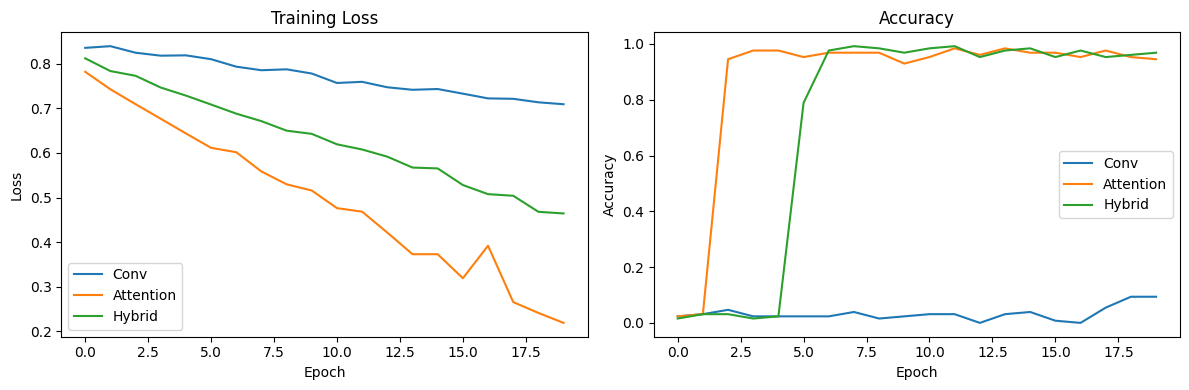

In [8]:
# Plot
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(loss_c, label="Conv")
plt.plot(loss_a, label="Attention")
plt.plot(loss_h, label="Hybrid")
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(acc_c, label="Conv")
plt.plot(acc_a, label="Attention")
plt.plot(acc_h, label="Hybrid")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()



==== Run 1/100 ====
[Conv] Epoch 1/20 | Loss: 0.8050 | Acc: 0.0000
[Conv] Epoch 2/20 | Loss: 0.7979 | Acc: 0.0703
[Conv] Epoch 3/20 | Loss: 0.7907 | Acc: 0.0234
[Conv] Epoch 4/20 | Loss: 0.7793 | Acc: 0.0078
[Conv] Epoch 5/20 | Loss: 0.7782 | Acc: 0.0078
[Conv] Epoch 6/20 | Loss: 0.7726 | Acc: 0.0312
[Conv] Epoch 7/20 | Loss: 0.7698 | Acc: 0.0234
[Conv] Epoch 8/20 | Loss: 0.7631 | Acc: 0.0391
[Conv] Epoch 9/20 | Loss: 0.7526 | Acc: 0.0312
[Conv] Epoch 10/20 | Loss: 0.7435 | Acc: 0.0234
[Conv] Epoch 11/20 | Loss: 0.7434 | Acc: 0.0312
[Conv] Epoch 12/20 | Loss: 0.7340 | Acc: 0.0312
[Conv] Epoch 13/20 | Loss: 0.7287 | Acc: 0.0156
[Conv] Epoch 14/20 | Loss: 0.7232 | Acc: 0.0391
[Conv] Epoch 15/20 | Loss: 0.7161 | Acc: 0.0234
[Conv] Epoch 16/20 | Loss: 0.7103 | Acc: 0.0000
[Conv] Epoch 17/20 | Loss: 0.7044 | Acc: 0.0000
[Conv] Epoch 18/20 | Loss: 0.6983 | Acc: 0.8906
[Conv] Epoch 19/20 | Loss: 0.6918 | Acc: 0.8516
[Conv] Epoch 20/20 | Loss: 0.6864 | Acc: 0.9844
[Attention] Epoch 1/20 | Los

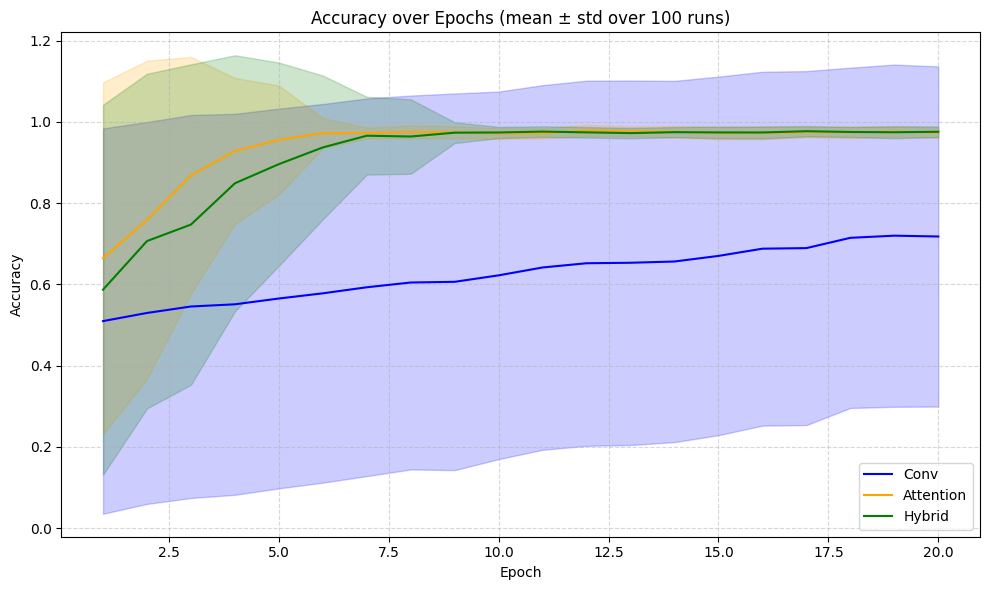

In [13]:
import numpy as np
import matplotlib.pyplot as plt

# Settings
N_RUNS = 100
EPOCHS = 20

# Storage: (runs x epochs)
acc_conv_all = []
acc_attn_all = []
acc_hybrid_all = []

for run in range(N_RUNS):
    print(f"\n==== Run {run + 1}/{N_RUNS} ====")

    # Re-initialize models each time
    conv_model = ConvPatternDetector(kernel_size=3)
    attn_model = AttentionPatternDetector(seq_len=30)
    hybrid_model = HybridPatternDetector(seq_len=30)

    # Train (each returns list of losses and list of accuracies)
    _, acc_c = train_model(conv_model, "Conv", epochs=EPOCHS)
    _, acc_a = train_model(attn_model, "Attention", epochs=EPOCHS)
    _, acc_h = train_model(hybrid_model, "Hybrid", epochs=EPOCHS)

    acc_conv_all.append(acc_c)
    acc_attn_all.append(acc_a)
    acc_hybrid_all.append(acc_h)

# Convert to numpy arrays: (runs x epochs)
acc_conv_all = np.array(acc_conv_all)
acc_attn_all = np.array(acc_attn_all)
acc_hybrid_all = np.array(acc_hybrid_all)
epochs = np.arange(1, EPOCHS + 1)

# Compute mean and std per epoch
def plot_with_std(data, label, color):
    mean = data.mean(axis=0)
    std = data.std(axis=0)
    plt.plot(epochs, mean, label=label, color=color)
    plt.fill_between(epochs, mean - std, mean + std, alpha=0.2, color=color)

# Plot
plt.figure(figsize=(10, 6))
plot_with_std(acc_conv_all, "Conv", "blue")
plot_with_std(acc_attn_all, "Attention", "orange")
plot_with_std(acc_hybrid_all, "Hybrid", "green")

plt.title("Accuracy over Epochs (mean ± std over 100 runs)")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


## layer comparison

In [14]:
import torch
import torch.nn as nn

class SimpleNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(100, 64)
        self.fc2 = nn.Linear(64, 64)
        self.fc3 = nn.Linear(64, 10)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        return self.fc3(x)


In [19]:
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

model = SimpleNet()
optimizer = optim.Adam(model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()

# Dummy data
x = torch.randn(128, 100)
y = torch.randint(0, 10, (128,))

# Track weight changes
layer_names = ['fc1', 'fc2', 'fc3']
prev_weights = {name: param.weight.clone().detach() for name, param in model.named_modules() if isinstance(param, nn.Linear)}
weight_changes = {name: [] for name in layer_names}

# Training loop
for epoch in range(30):
    model.train()
    optimizer.zero_grad()

    out = model(x)
    loss = criterion(out, y)
    loss.backward()
    optimizer.step()

    # Track L2 norm of weight change for each layer
    for name, layer in model.named_modules():
        if isinstance(layer, nn.Linear):
            delta = torch.norm(layer.weight.detach() - prev_weights[name]).item()
            weight_changes[name].append(delta)
            prev_weights[name] = layer.weight.clone().detach()

    print(f"Epoch {epoch+1:2d}, Loss: {loss.item():.4f}")


Epoch  1, Loss: 2.2982
Epoch  2, Loss: 2.2829
Epoch  3, Loss: 2.2681
Epoch  4, Loss: 2.2537
Epoch  5, Loss: 2.2394
Epoch  6, Loss: 2.2251
Epoch  7, Loss: 2.2109
Epoch  8, Loss: 2.1968
Epoch  9, Loss: 2.1825
Epoch 10, Loss: 2.1681
Epoch 11, Loss: 2.1533
Epoch 12, Loss: 2.1382
Epoch 13, Loss: 2.1228
Epoch 14, Loss: 2.1068
Epoch 15, Loss: 2.0905
Epoch 16, Loss: 2.0736
Epoch 17, Loss: 2.0563
Epoch 18, Loss: 2.0383
Epoch 19, Loss: 2.0196
Epoch 20, Loss: 2.0002
Epoch 21, Loss: 1.9799
Epoch 22, Loss: 1.9589
Epoch 23, Loss: 1.9371
Epoch 24, Loss: 1.9144
Epoch 25, Loss: 1.8908
Epoch 26, Loss: 1.8664
Epoch 27, Loss: 1.8410
Epoch 28, Loss: 1.8146
Epoch 29, Loss: 1.7871
Epoch 30, Loss: 1.7587


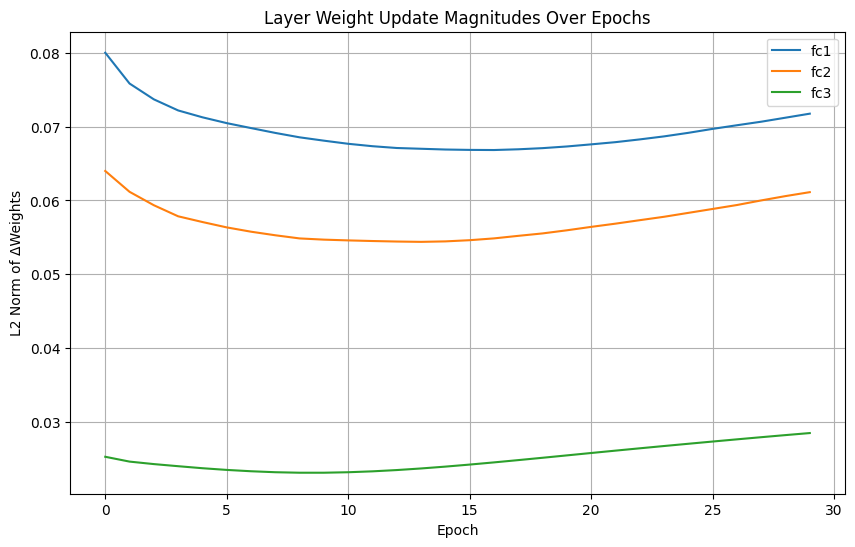

In [20]:
plt.figure(figsize=(10, 6))
for name in layer_names:
    plt.plot(weight_changes[name], label=name)

plt.title("Layer Weight Update Magnitudes Over Epochs")
plt.xlabel("Epoch")
plt.ylabel("L2 Norm of ΔWeights")
plt.legend()
plt.grid(True)
plt.show()


In [4]:
# Parameters
w1, b1 = 2.0, 3.0
w2, b2 = -1.0, 0.5
w3, b3 = 0.1, -2.0

# Input
x = 1.0

output_list = []
for x in range(30):
# Forward pass (no activation functions)
    z1 = w1 * x + b1
    z2 = w2 * z1 + b2
    output = w3 * z2 + b3
    output_list.append(output) 

print("Output:", output)


Output: -8.05


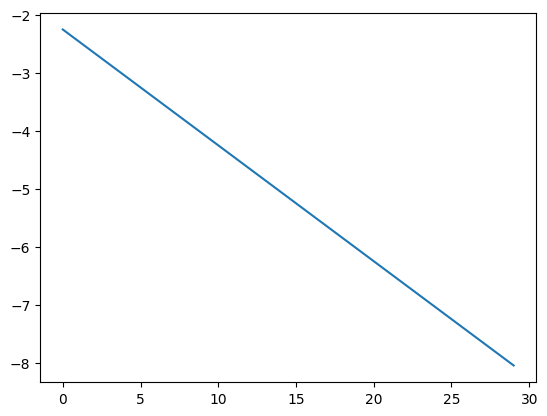

In [5]:
import matplotlib.pyplot as plt
plt.plot(output_list)

In [10]:
def relu(z):
    return max(0, z)

non_linier_output_list = []
for x in range(-30, 30):
    # Forward pass with ReLU activation
    z1 = relu(w1 * x + b1)
    z2 = relu(w2 * z1 + b2)
    output = w3 * z2 + b3
    non_linier_output_list.append(output)

    z1 = relu(w1 * x + b1)
    z2 = relu(w2 * z1 + b2)
    y = w3 * z2 + b3
    ys_relu.append(y)


print("Output with ReLU:", output)


Output with ReLU: -2.0


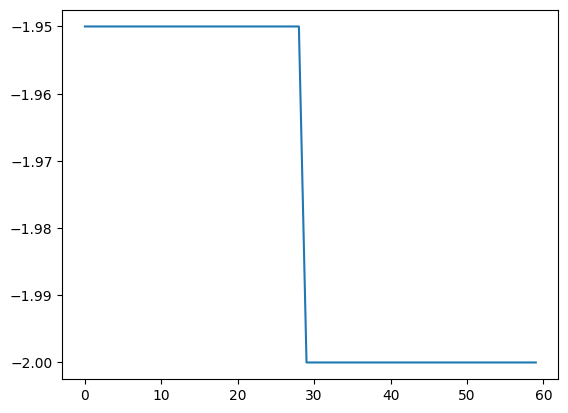

In [11]:
plt.plot(non_linier_output_list)

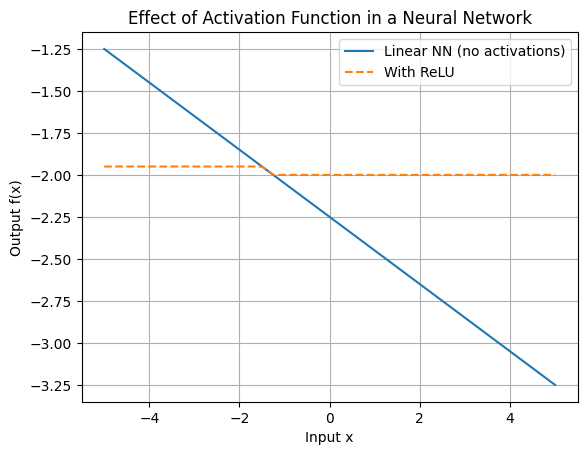

In [13]:
import numpy as np
import matplotlib.pyplot as plt

xs = np.linspace(-5, 5, 200)
ys_linear = []
ys_relu = []

for x in xs:
    # No activation
    z1 = w1 * x + b1
    z2 = w2 * z1 + b2
    y = w3 * z2 + b3
    ys_linear.append(y)

    # With ReLU
    z1 = relu(w1 * x + b1)
    z2 = relu(w2 * z1 + b2)
    y = w3 * z2 + b3
    ys_relu.append(y)

plt.plot(xs, ys_linear, label="Linear NN (no activations)")
plt.plot(xs, ys_relu, label="With ReLU", linestyle='--')
plt.legend()
plt.grid(True)
plt.title("Effect of Activation Function in a Neural Network")
plt.xlabel("Input x")
plt.ylabel("Output f(x)")
plt.show()


## Activation functions comparison

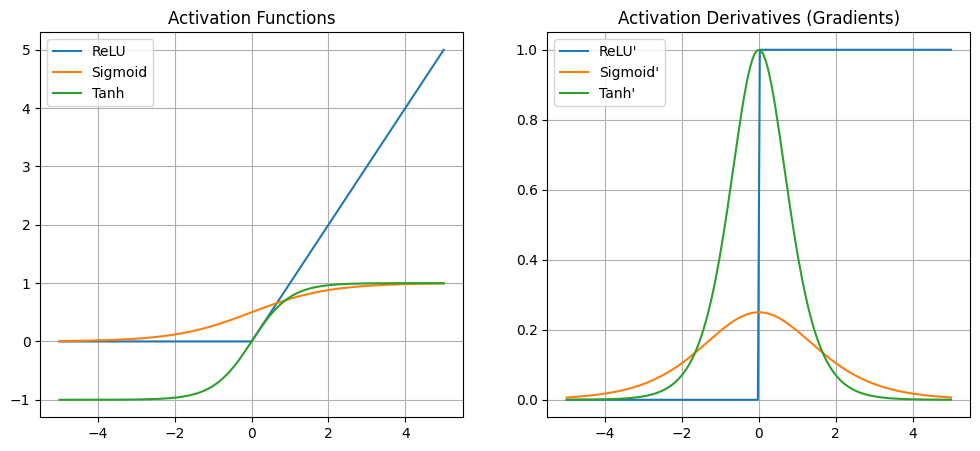

In [14]:
import numpy as np
import matplotlib.pyplot as plt

# Define activation functions and derivatives
def relu(x):
    return np.maximum(0, x)

def relu_derivative(x):
    return (x > 0).astype(float)

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_derivative(x):
    s = sigmoid(x)
    return s * (1 - s)

def tanh(x):
    return np.tanh(x)

def tanh_derivative(x):
    return 1 - np.tanh(x)**2

# Inputs
x_vals = np.linspace(-5, 5, 200)

# Plot activations
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(x_vals, relu(x_vals), label="ReLU")
plt.plot(x_vals, sigmoid(x_vals), label="Sigmoid")
plt.plot(x_vals, tanh(x_vals), label="Tanh")
plt.title("Activation Functions")
plt.legend()
plt.grid(True)

# Plot derivatives
plt.subplot(1, 2, 2)
plt.plot(x_vals, relu_derivative(x_vals), label="ReLU'")
plt.plot(x_vals, sigmoid_derivative(x_vals), label="Sigmoid'")
plt.plot(x_vals, tanh_derivative(x_vals), label="Tanh'")
plt.title("Activation Derivatives (Gradients)")
plt.legend()
plt.grid(True)

plt.show()


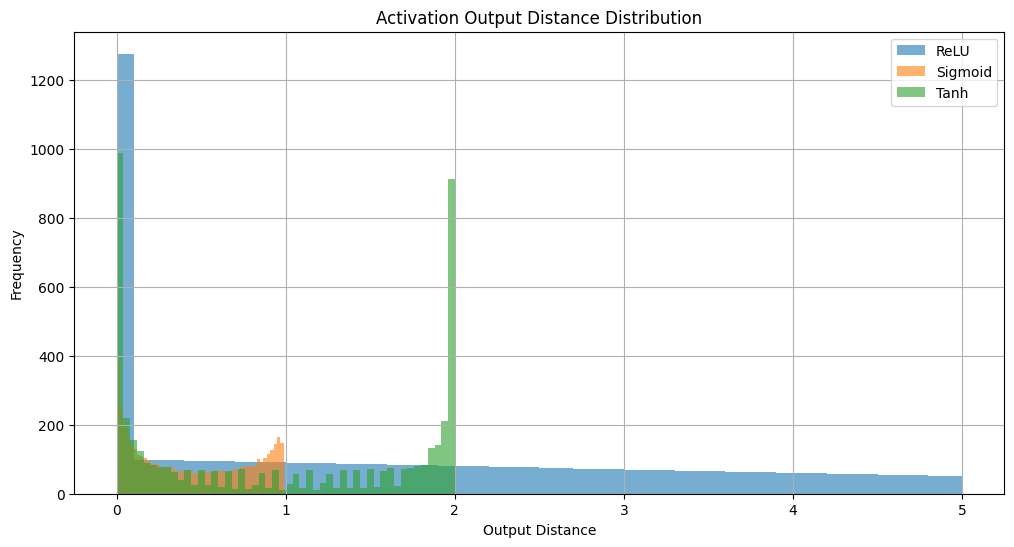

In [21]:
import numpy as np
import matplotlib.pyplot as plt

# Activation functions
def relu(x):
    return np.maximum(0, x)

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def tanh(x):
    return np.tanh(x)

# Input space
x_vals = np.linspace(-5, 5, 100)
pairs = [(xi, xj) for i, xi in enumerate(x_vals) for xj in x_vals[i+1:]]

# Distance calculations
def pairwise_diffs(func):
    return [abs(func(x1) - func(x2)) for x1, x2 in pairs]

relu_dists = pairwise_diffs(relu)
sigmoid_dists = pairwise_diffs(sigmoid)
tanh_dists = pairwise_diffs(tanh)

# Histogram comparison
plt.figure(figsize=(12, 6))
plt.hist(relu_dists, bins=50, alpha=0.6, label='ReLU')
plt.hist(sigmoid_dists, bins=50, alpha=0.6, label='Sigmoid')
plt.hist(tanh_dists, bins=50, alpha=0.6, label='Tanh')
plt.xlabel('Output Distance')
plt.ylabel('Frequency')
plt.title('Activation Output Distance Distribution')
plt.legend()
plt.grid(True)
plt.show()
